# Precision–Recall Curve

**Family:** Scientific & clinical &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Scientific & clinical:* Specialised plots for statistics, biomedical research and model evaluation.

## Design purpose

Plots precision (positive predictive value) against recall (sensitivity) across thresholds. Unlike ROC, it focuses on the positive class, so it stays honest when positives are rare.

## When to use

- Evaluate classifiers on imbalanced data (rare disease screening, fraud, defects)
- Show the cost of false positives when chasing more recall

## Avoid when

- Classes are balanced and both matter equally (ROC is more familiar)
- Comparing PR curves across datasets with different prevalence (the baselines differ)

## Alternatives

- ROC curve
- Precision/recall versus threshold line chart

## Design tips

- Draw the no-skill baseline at the prevalence (positive-class rate)
- Report average precision (AP) in the legend

## Example

Screening model for a rare outcome (about 8% prevalence), comparing two classifiers.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve, average_precision_score

### Data

In [2]:
X, y = make_classification(n_samples=6000, n_features=20, n_informative=6, weights=[0.92],
                           flip_y=0.02, random_state=1)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.4, random_state=1, stratify=y)
models = {"Logistic regression": LogisticRegression(max_iter=1000),
          "Random forest": RandomForestClassifier(n_estimators=300, random_state=1)}
scores = {name: m.fit(X_tr, y_tr).predict_proba(X_te)[:, 1] for name, m in models.items()}
df = pd.DataFrame({"y_true": y_te, **scores})
print(f"prevalence = {df.y_true.mean():.3f}")
df.head()

prevalence = 0.090


,y_true,Logistic regression,Random forest
0,0,0.054348,0.023333
1,0,0.016626,0.006667
2,0,0.012530,0.016667
3,0,0.317785,0.273333
4,0,0.021379,0.006667


### Plot

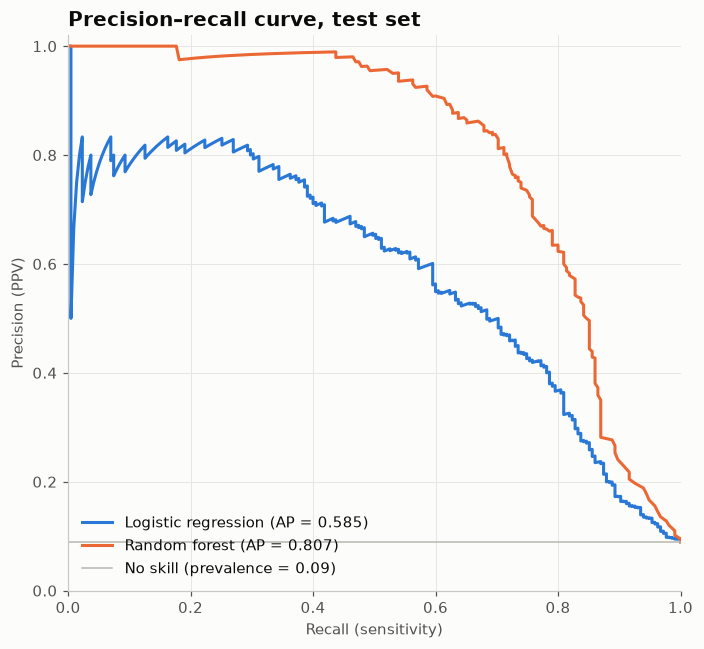

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for i, name in enumerate(scores):
    p, r, _ = precision_recall_curve(df["y_true"], df[name])
    ap = average_precision_score(df["y_true"], df[name])
    ax.plot(r, p, color=PALETTE[i], label=f"{name} (AP = {ap:.3f})")
prev = df["y_true"].mean()
ax.axhline(prev, color=GRAY, linewidth=1, label=f"No skill (prevalence = {prev:.2f})")
ax.set_xlabel("Recall (sensitivity)"); ax.set_ylabel("Precision (PPV)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_title("Precision–recall curve, test set")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

## How to read it

Moving right catches more true cases (recall), usually at the cost of more false alarms (lower precision). A curve that stays high for longer is better. The gray line is what random guessing achieves.

## Try it with real data

**Source:** sklearn.datasets.load_breast_cancer() — Wisconsin diagnostic breast cancer, 569 tumours (malignant = positive), bundled with scikit-learn

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [4]:
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
bc = load_breast_cancer()
X, y = bc.data, 1 - bc.target                       # 1 = malignant
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.4, random_state=1, stratify=y)

models = {"Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
          "Random forest": RandomForestClassifier(n_estimators=300, random_state=1)}
scores = {name: m.fit(X_tr, y_tr).predict_proba(X_te)[:, 1] for name, m in models.items()}
df = pd.DataFrame({"y_true": y_te, **scores})
print(f"prevalence = {df.y_true.mean():.3f}")
df.head()

prevalence = 0.373


,y_true,Logistic regression,Random forest
0,0,8.832048e-06,0.013333
1,0,2.394772e-07,0.000000
2,1,9.633918e-01,0.990000
3,1,9.962619e-01,0.983333
4,1,9.982830e-01,0.993333


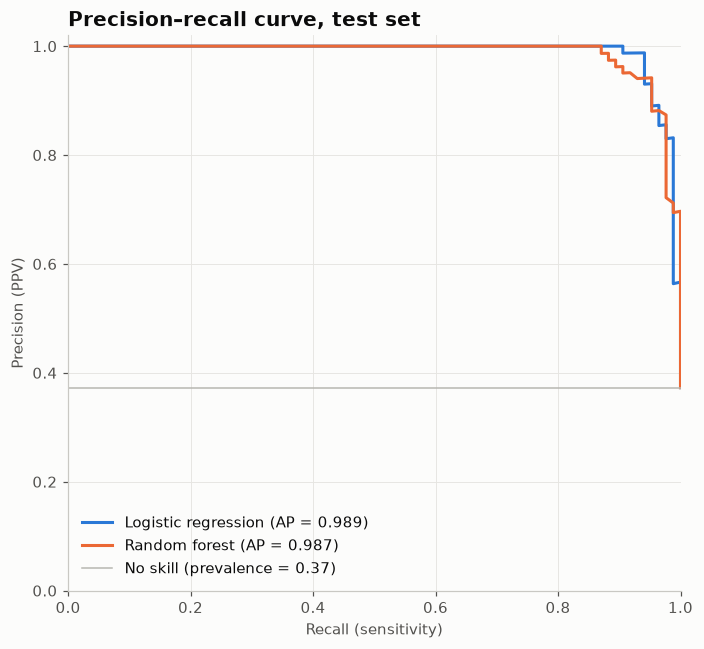

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for i, name in enumerate(scores):
    p, r, _ = precision_recall_curve(df["y_true"], df[name])
    ap = average_precision_score(df["y_true"], df[name])
    ax.plot(r, p, color=PALETTE[i], label=f"{name} (AP = {ap:.3f})")
prev = df["y_true"].mean()
ax.axhline(prev, color=GRAY, linewidth=1, label=f"No skill (prevalence = {prev:.2f})")
ax.set_xlabel("Recall (sensitivity)"); ax.set_ylabel("Precision (PPV)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_title("Precision–recall curve, test set")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

---
Standalone script: [`precision_recall_curve.py`](precision_recall_curve.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)